# Google Visualizationn Function
This cell is straight from googles notebook it draws the bounding box and category of every match.

In [33]:
import cv2
import numpy as np

MARGIN = 10  # pixels
ROW_SIZE = 10  # pixels
FONT_SIZE = 1
FONT_THICKNESS = 1
TEXT_COLOR = (255, 0, 0)  # red


def visualize(
    image,
    detection_result
) -> np.ndarray:
  """Draws bounding boxes on the input image and return it.
  Args:
    image: The input RGB image.
    detection_result: The list of all "Detection" entities to be visualize.
  Returns:
    Image with bounding boxes.
  """
  for detection in detection_result.detections:
    # Draw bounding_box
    bbox = detection.bounding_box
    start_point = bbox.origin_x, bbox.origin_y
    end_point = bbox.origin_x + bbox.width, bbox.origin_y + bbox.height
    cv2.rectangle(image, start_point, end_point, TEXT_COLOR, 3)

    # Draw label and score
    category = detection.categories[0]
    category_name = category.category_name
    probability = round(category.score, 2)
    result_text = category_name + ' (' + str(probability) + ')'
    text_location = (MARGIN + bbox.origin_x,
                     MARGIN + ROW_SIZE + bbox.origin_y)
    cv2.putText(image, result_text, text_location, cv2.FONT_HERSHEY_PLAIN,
                FONT_SIZE, TEXT_COLOR, FONT_THICKNESS)

  return image

# Classify every person and print result
This classifies all people in the image and saves the bounding boxes.

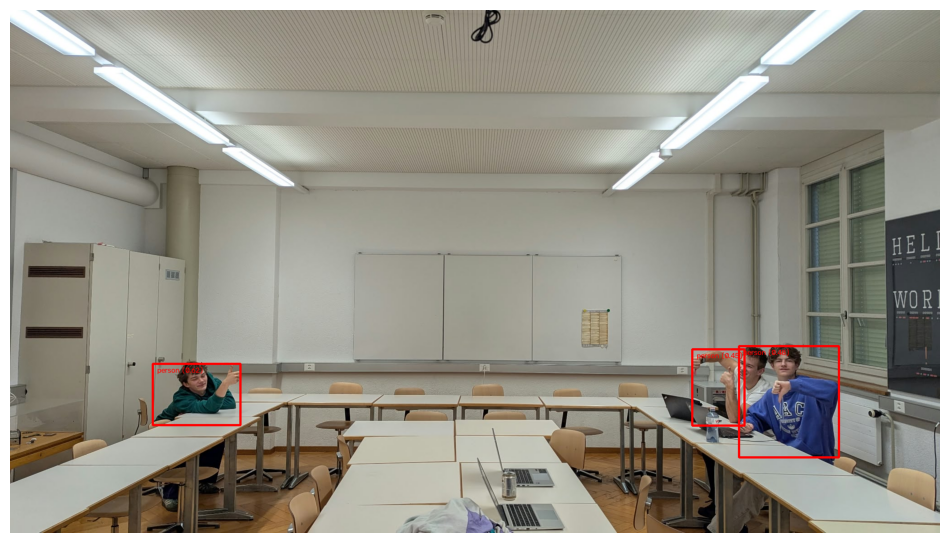

In [34]:
# STEP 1: Import the necessary modules.
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from pathlib import Path

IMAGE_FILE = Path("resources/images/class-data-set/class0.jpeg")

# STEP 2: Create an ObjectDetector object.
base_options = python.BaseOptions(model_asset_path='resources/model/efficientdet_lite0.tflite')
options = vision.ObjectDetectorOptions(base_options=base_options,
                                       score_threshold=0.3,
                                       category_allowlist=["person"])
detector = vision.ObjectDetector.create_from_options(options)

image = mp.Image.create_from_file(str(IMAGE_FILE))

detection_result = detector.detect(image)

image_copy = np.copy(image.numpy_view())
annotated_image = visualize(image_copy, detection_result)
rgb_annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)

import cv2
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(rgb_annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

bboxs = [r.bounding_box for r in detection_result.detections]

# Cropping
This cell makes a cropped image for every person.

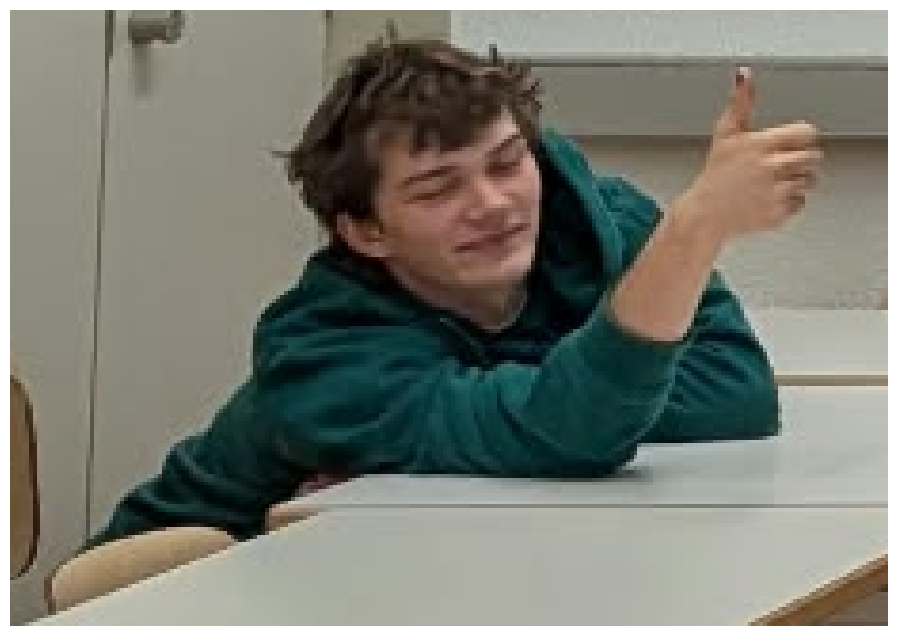

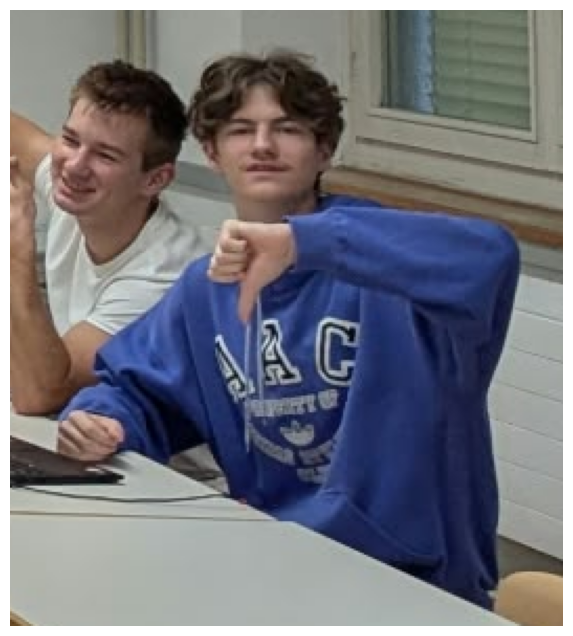

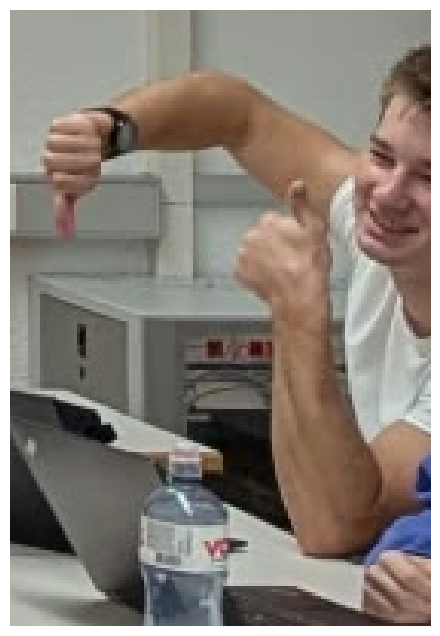

In [35]:
from PIL import Image
def get_crops(bboxs):
    im = Image.open(r'resources/images/class-data-set/class0.jpeg')
    images =[]
    for people in bboxs:
        tl_x = people.origin_x - (0.1*people.width)
        tl_y = people.origin_y - (0.1*people.height)
        br_x = people.origin_x + people.width + (0.1*people.width)
        br_y = people.origin_y + people.height + (0.1*people.height)

        cropped_image = im.crop((tl_x, tl_y, br_x, br_y))
        images.append(cropped_image)

    return images

crops = get_crops(bboxs)

for image in crops:
    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

# Gesture Recognition
This cell classifies the most prominent gesture in every cropped image.

In [36]:
base_gesture_options = python.BaseOptions(model_asset_path='resources/model/gesture_recognizer.task')
gesture_options = vision.GestureRecognizerOptions(base_options=base_gesture_options)
gesture_recognizer = vision.GestureRecognizer.create_from_options(gesture_options)

for crop in crops:
    crop.convert('RGB')
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.asarray(crop))
    recognition_result = gesture_recognizer.recognize(mp_image)

    top_gesture = recognition_result.gestures[0][0]

    print(top_gesture)


Category(index=-1, score=0.6085725426673889, display_name=None, category_name='Thumb_Up')
Category(index=-1, score=0.8525888323783875, display_name=None, category_name='Thumb_Down')
Category(index=-1, score=0.6495025753974915, display_name=None, category_name='Thumb_Down')


In [40]:
import pandas as pd

names = ["pos", "neg", "other"]
correct = pd.read_csv('resources/images/class-data-set/correct.csv', names=names)
correct

,pos,neg,other
0,1,2,0
1,4,5,1
2,4,6,2
3,5,7,2
4,11,4,0
5,8,4,0
6,3,6,5
